In [2]:
#| include: false
%load_ext autoreload
%autoreload 2

In [169]:
#| include: false
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, MeanShift, estimate_bandwidth

from pathlib import Path
from itertools import product

from miia_pec1.plot import plot_image, plot_histogram, plot_list_images, plot_3d_gray

plt.rcParams['figure.dpi'] = 100
plt.rcParams['figure.figsize'] = (6, 4.5)

In [4]:
#| include: false
ROOT_DIR = Path().cwd()
DATA_DIR = ROOT_DIR / 'data'
THRESHOLD_DIR = DATA_DIR / 'threshold'

## Umbralización

### Umbralización global

La umbralización global utiliza un único umbral para segmentar toda la imagen.

$$
dst(x,y)=
\begin{cases}
valor_x, & \text{si } src(x,y)>thresh \\
valor_y, & \text{si } src(x,y)\leq thresh
\end{cases}
$$

Donde:

- $valor_x$: valor asignado cuando se supera el umbral.
- $valor_y$: valor asignado cuando no se supera el umbral.

Los principales tipos de umbralización son:

- **Binaria:** Asigna el valor `maxValue` si el valor del píxel el mayor que el umbral y 0 en caso contrario.
- **Binaria inversa:** Invierte los valores asignados por la umbralización binaria.
- **Truncamiento:** Asigna el valor umbral si el el valor del píxel es mayor que el umbral, de lo contrario asigna el valor original del píxel.
- **Puesta a cero:** Conversa los valores mayores que el umbral y el resto las sustituye por 0.
- **Puesta a cero invertido:** Conserva los valores menores o iguales al umbral y el resto los sustituye por 0.

Los histogramas de la @fig-global-threshold-histogram permiten analizar cómo se modifica la distribución de intensidades con cada método. Mientras las umbralizaciones binarias concentran los píxeles en dos valores, los métodos de truncamiento y puesta a cero conservan parte de las intensidades originales.

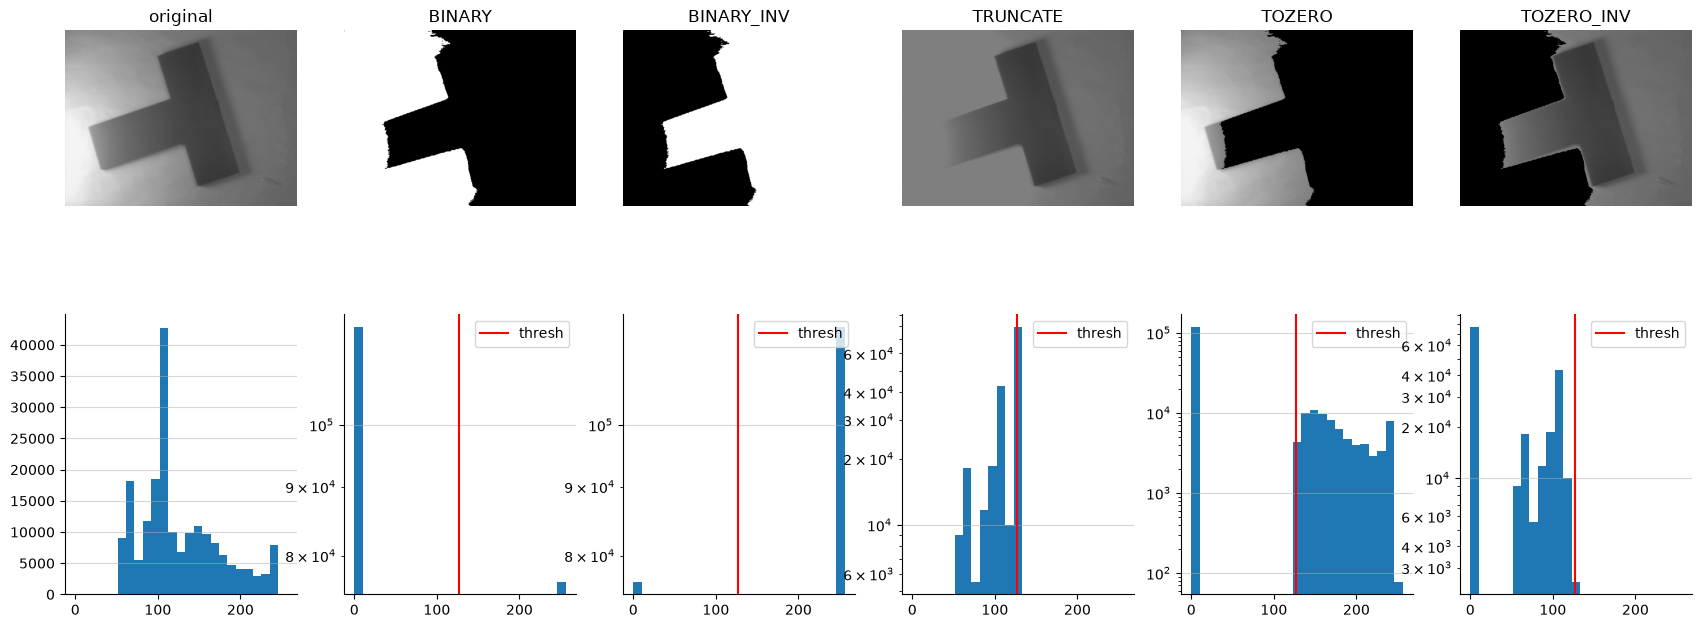

In [5]:
#| echo: false
#| label: fig-global-threshold-histogram
#| fig-cap: "Distribución de intensidades tras aplicar los distintos métodos de umbralización global"
THRESH_VALUE = 127
thresholds = {
    'BINARY': cv.THRESH_BINARY,
    'BINARY_INV': cv.THRESH_BINARY_INV,
    'TRUNCATE': cv.THRESH_TRUNC,
    'TOZERO': cv.THRESH_TOZERO,
    'TOZERO_INV': cv.THRESH_TOZERO_INV
}
images = [{
    'path': THRESHOLD_DIR / 'TH_noisy2.png',
    }, {
    'path': THRESHOLD_DIR / 'TH_TE.gif'
    }, {
    'path': THRESHOLD_DIR / 'TH_scanTable.png'
}]


for img in images:
    path = img['path']
    img['name'] = path.stem
    img['array'] = cv.imread(path, cv.IMREAD_GRAYSCALE)


img = images[1]['array']

fig, axes = plt.subplots(2, 6, figsize=(21, 8))
axes = axes.ravel()

plot_image(img, ax=axes[0], title='original')
plot_histogram(img, ax=axes[6], bins=25)

for i, (name, thresh_type) in enumerate(thresholds.items(), 1):
        _, dst = cv.threshold(img, THRESH_VALUE, 255, thresh_type)
        plot_image(dst, ax=axes[i], title=name)
        plot_histogram(dst, ax=axes[i+6], bins=25, thresh=THRESH_VALUE, scale='log')

En la @fig-global-threshold se puede observar que los resultados son dependientes del contraste y la iluminación de cada imagen.

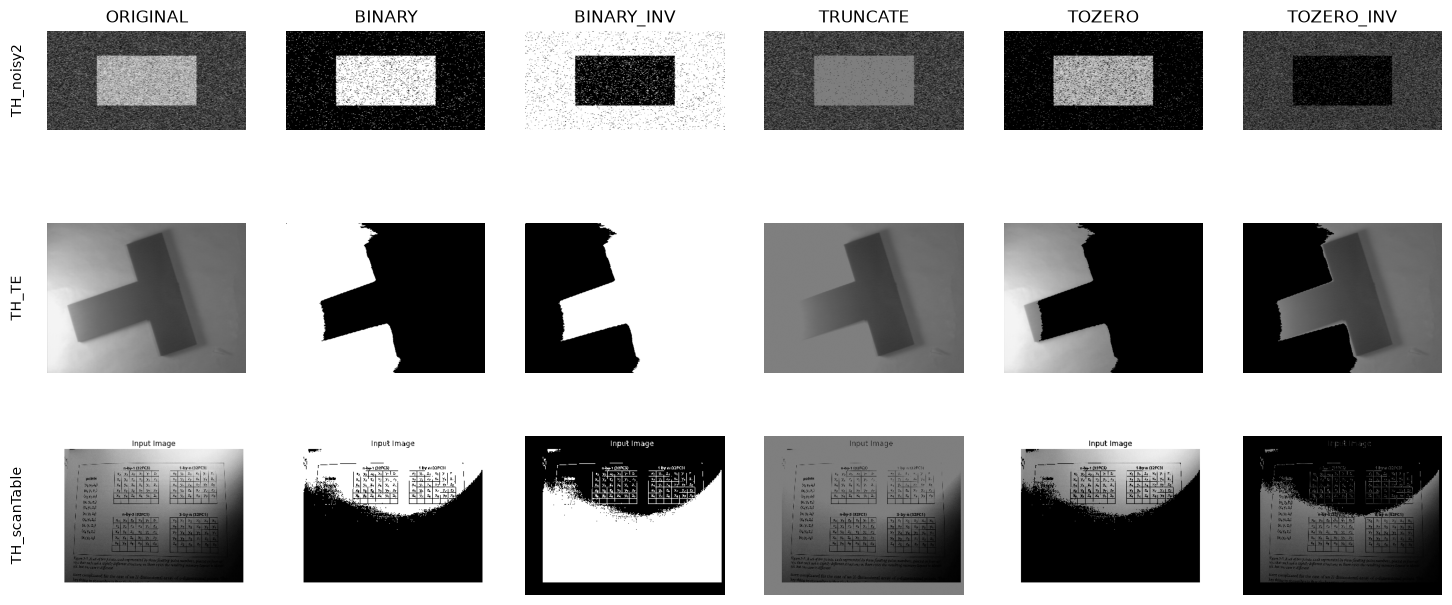

In [6]:
#| echo: false
#| label: fig-global-threshold
#| fig-cap: "Comparación de los métodos de umbralización global (umbral = 127)"
THRESH_VALUE = 127
rows = len(images)
cols = len(thresholds) + 1


fig, axes = plt.subplots(rows, cols, figsize=(18, 8))
axes = axes.ravel()

for i, img in enumerate(images):
    idx = i*cols
    plot_image(img['array'], ax=axes[idx], title='ORIGINAL' if i==0 else None)

    for j, (name, thresh_type) in enumerate(thresholds.items(), 1):
        _, dst = cv.threshold(img['array'], THRESH_VALUE, 255, thresh_type)
        plot_image(dst, ax=axes[idx + j], title=name if i==0 else None)

    axes[idx].text(
        -0.15, 0.5, img['name'],
        transform=axes[idx].transAxes,
        rotation=90,
        va='center',
        ha='center'
    )

plt.show()

### Umbralización local

La umbralización local, calcula un umbral $T(x, y)$ para cada píxel a partir de una ventana centrada en él.

Dentro de las ventana OpenCV utiliza dos métodos para calcular el umbral:

- **Media:** El umbral es la media del área vecina menos una constante $C$.
- **Gaussiana:** El umbral es una media ponderada gaussiana del área vecina menos una constante $C$.

En la @fig-local-vs-global-threshold se muestra como la umbralización local, permite recuperar una mayor cantidad de detalles que la umbralización global sobre imágenes que presentan variaciones en la iluminación, ya permite ajustar el umbral de cada zona, las zonas iluminadas tendrán un umbral alto mientras que las oscuras presentarán uno más bajo.

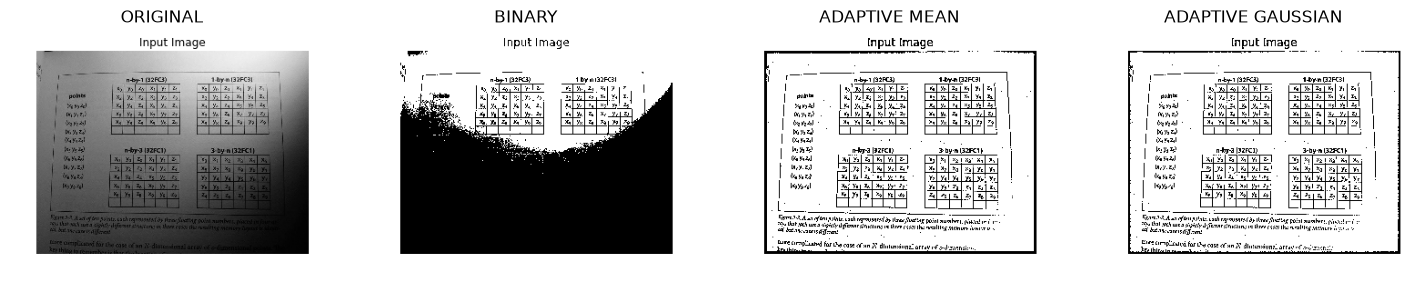

In [ ]:
#| echo: false
#| label: fig-local-vs-global-threshold
#| fig-cap: "Umbralización global vs umbralización local"
img = images[-1]['array']

fig, axes = plt.subplots(1, 4, figsize=(18, 6))

_, th1 = cv.threshold(img, 127, 255, cv.THRESH_BINARY)
th2 = cv.adaptiveThreshold(img, 255, cv.ADAPTIVE_THRESH_MEAN_C, cv.THRESH_BINARY, 7, 8)
th3 = cv.adaptiveThreshold(img, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, 7, 8)

plot_image(img, ax=axes[0], title='ORIGINAL')
plot_image(th1, ax=axes[1], title='BINARY')
plot_image(th2, ax=axes[2], title='ADAPTIVE MEAN')
plot_image(th3, ax=axes[3], title='ADAPTIVE GAUSSIAN')

plt.show()

En la @fig-local-threshold-params se observa como al aumentar el valor de $C$ se reduce la presencia de píxeles negros aislados en el fondo, mientras que el valor de `blockSize` determina el tamaño de la la extensión que se utiliza para calcular el umbral.

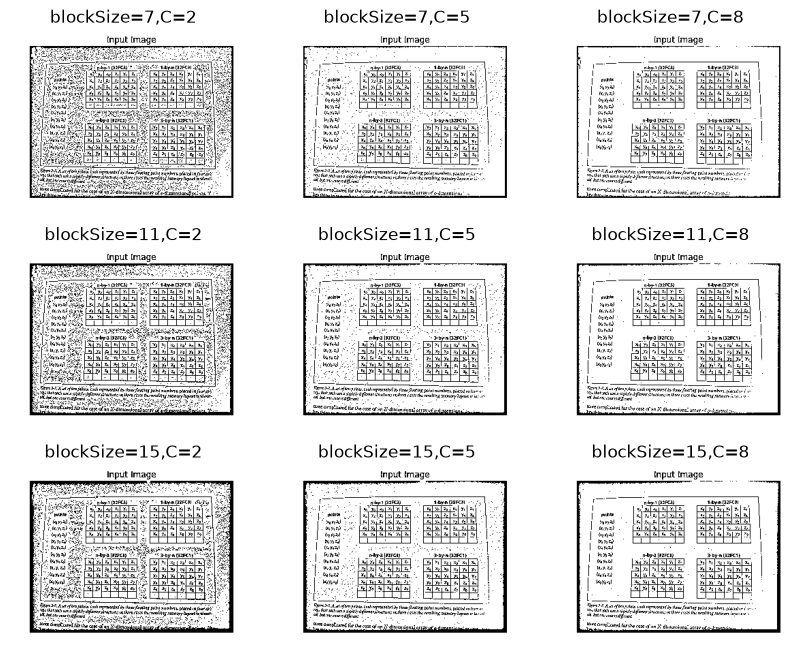

In [ ]:
#| echo: false
#| label: fig-local-threshold-params
#| fig-cap: "Ajuste de parámetros para la umbralización local"
img = images[-1]['array']

fig, axes = plt.subplots(3, 3, figsize=(10, 8))
axes = axes.ravel()

for i, (blockSize, C) in enumerate(product((7, 11, 15), (2, 5, 8))):
    th = cv.adaptiveThreshold(img, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, blockSize, C)
    plot_image(th, ax=axes[i], title=f'blockSize={blockSize},C={C}')

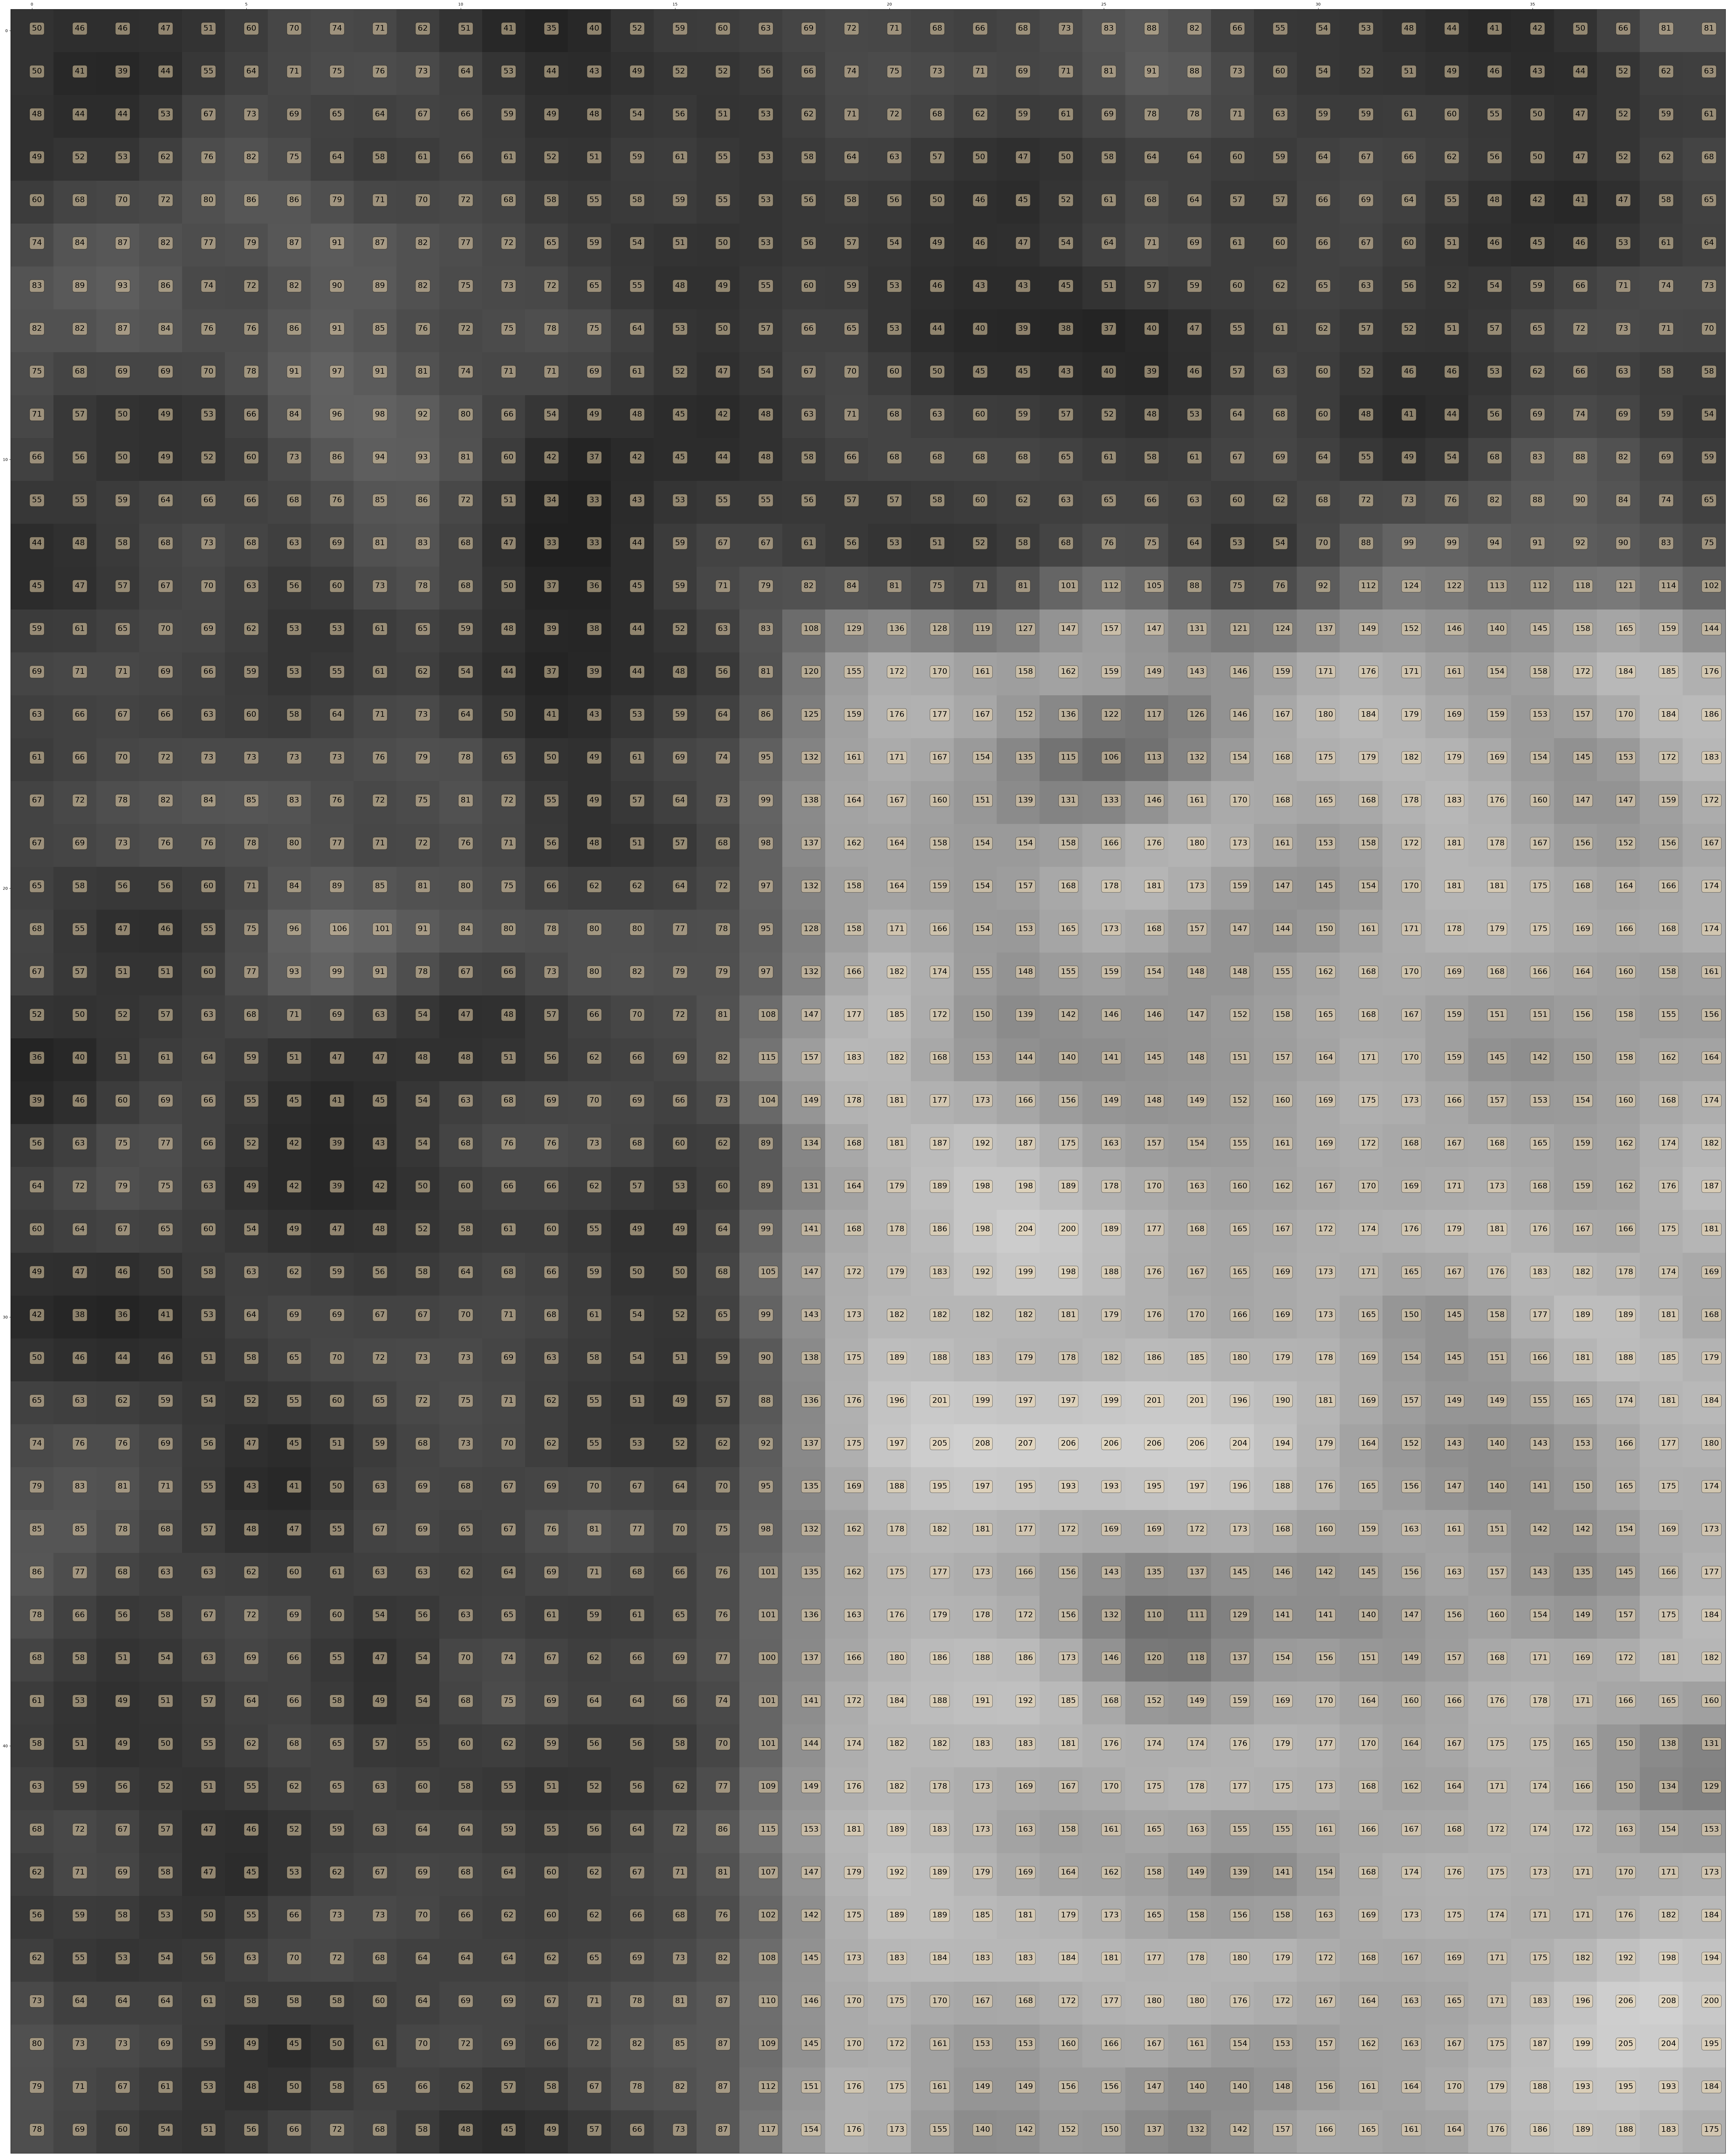

In [9]:
#| include: false
img = images[0]['array']
blur = cv.GaussianBlur(img, ksize=(5, 5), sigmaX=0)

recorte = blur[50:100, 110:150].copy()

fig, ax = plt.subplots(figsize=(200, 100))
ax = plot_image(recorte, ax= ax, axis=True)

for x in range(40):
    for y in range(50):
        ax.text(x, y, recorte[y, x], fontsize=20, bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.show()

Se analiza si es posible segmentar completamente el réctangulo de la imagen TH_noisy2.png o la pieza en forma de T de TH_TE.gif utilizando únicamente umbralazación local.

Para analizar el efecto del tamaño de la ventana, sobre el resultado, se selecciona un recorte que contiene parte del rectángulo y del fondo.

En la @fig-local-threshold-blocksize, se observa como una ventana más pequeña, produce una segementación más fragmentada, dado que el umbral se calcula a partir de una región reducida de píxeles vecinos que tienen intensidades similares al píxel central de la ventana. Al aumentar el tamaño de la ventana está incorpora píxeles de las dos regiones del recorte lo que favorece su diferenciación asemejando su comportamiento a una umbralización global.

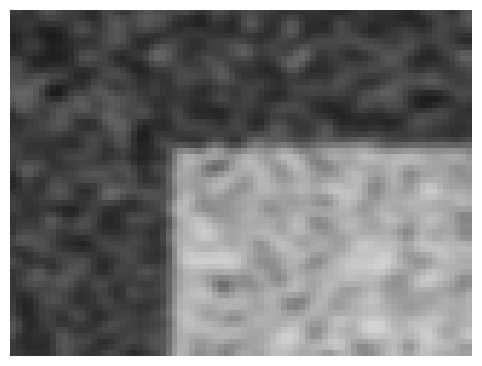

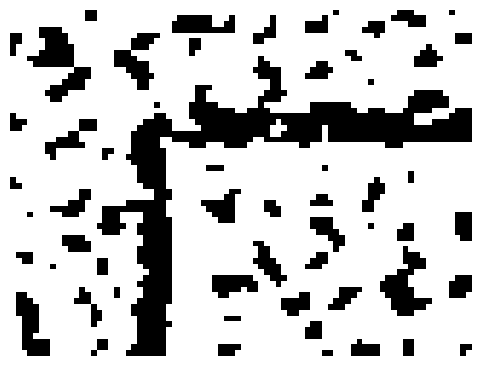

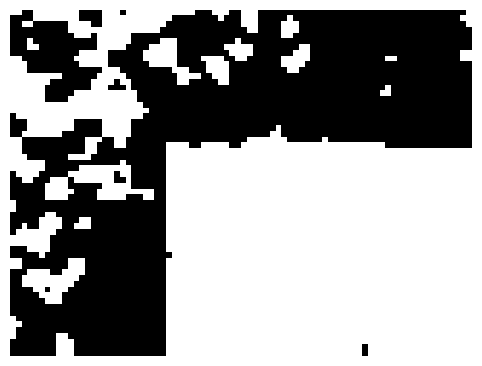

In [10]:
#| echo: false
#| label: fig-local-threshold-blocksize
#| fig-cap: "Análisis de la umbralización local en regiones homogéneas"
#| fig-subcap:
#|  - "Recorte de una región"
#|  - "Umbralización con una ventana pequeña (blockSize=15)"
#|  - "Umbralización con una ventana grande (blockSize=81)"
#| layout-ncol: 3
recorte = blur[40:100, 100:180].copy()

th1 = cv.adaptiveThreshold(recorte, 255, cv.ADAPTIVE_THRESH_MEAN_C, cv.THRESH_BINARY, 15, 12)
th2 = cv.adaptiveThreshold(recorte, 255, cv.ADAPTIVE_THRESH_MEAN_C, cv.THRESH_BINARY, 81, 12)


plot_image(recorte)
plot_image(th1)
plot_image(th2)

plt.show()

Como se muestra en las figuras @fig-local-rectangle y @fig-local-t, es posible obtener una segmentación bastante completa utilizando tamaños de ventana grandes, para que las ventanas incluyan píxeles del objeto que estamos buscando segmentar y del fondo.

En el caso del rectángulo se obtiene un buen resultado con `blockSize=511` y $C=10$, mientras que para la pieza en forma de T el mejor resultado se obtiene con `blockSize=501` y $C=20$.

Sin embargo, ninguna de las configuraciones consigue una segmentación completa y sin errores, habría que considerar otras técnicas.

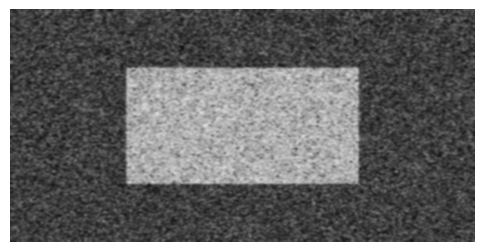

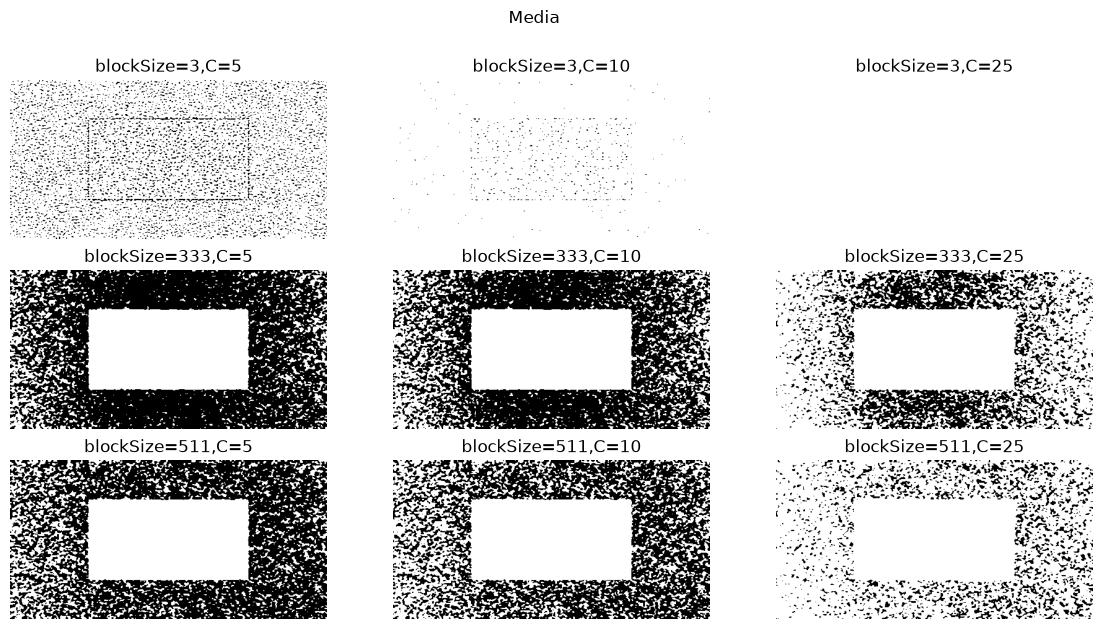

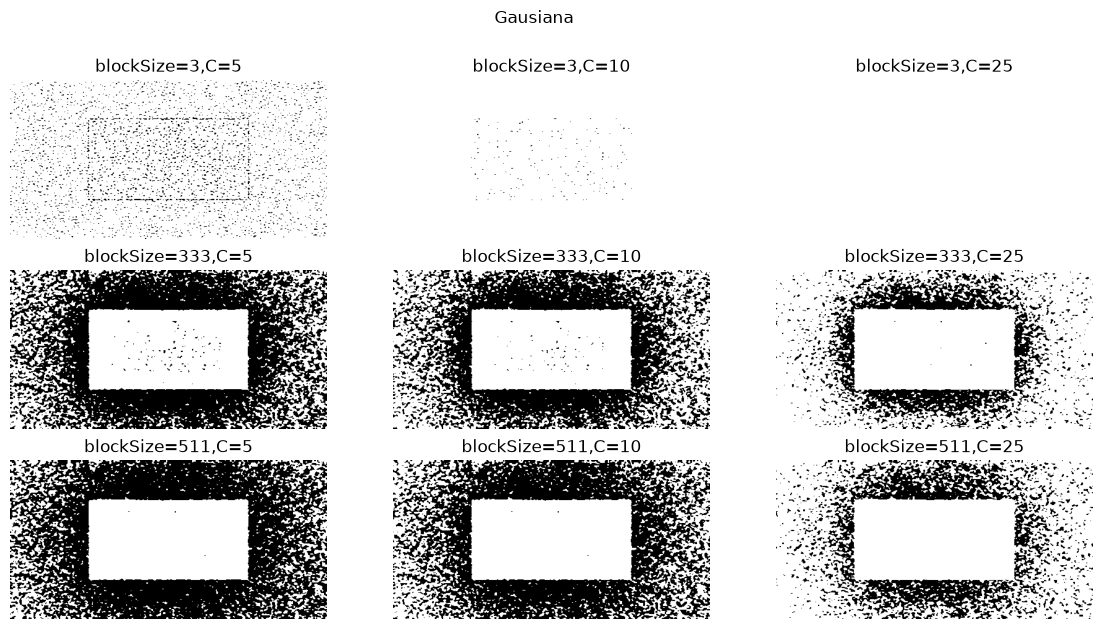

In [11]:
#| echo: false
#| label: fig-local-rectangle
#| fig-cap: "Ajuste de parámetros para la umbralización local"
#| fig-subcap:
#|  - "Imagen original"
#|  - "Aplicación de umbralización local, usando la media"
#|  - "Aplicación de umbralización local, usando la gausiana"
#| layout: [[1], [1, 1]]
img = images[0]['array']
blur = cv.GaussianBlur(img, ksize=(5, 5), sigmaX=0)
th = cv.adaptiveThreshold(blur, 255, cv.ADAPTIVE_THRESH_MEAN_C, cv.THRESH_BINARY, 19, 12)

plot_image(blur)

for metodo in (cv.ADAPTIVE_THRESH_MEAN_C, cv.ADAPTIVE_THRESH_GAUSSIAN_C):
    fig, axes = plt.subplots(3, 3, figsize=(14, 7))
    axes = axes.ravel()

    for i ,(blockSize, C) in enumerate(product((3, 333, 511), (5, 10, 25))):
        th = cv.adaptiveThreshold(blur, 255, metodo, cv.THRESH_BINARY, blockSize, C)
        plot_image(th, ax=axes[i], title=f'blockSize={blockSize},C={C}')

    fig.suptitle('Media' if metodo==cv.ADAPTIVE_THRESH_MEAN_C else 'Gausiana')

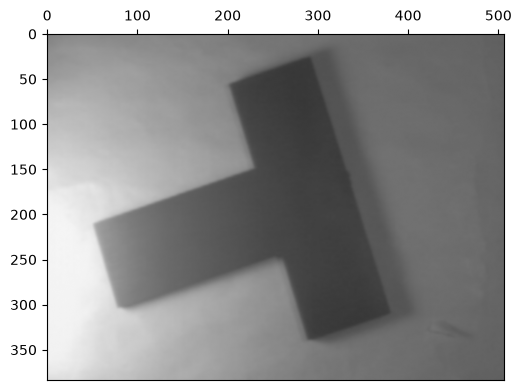

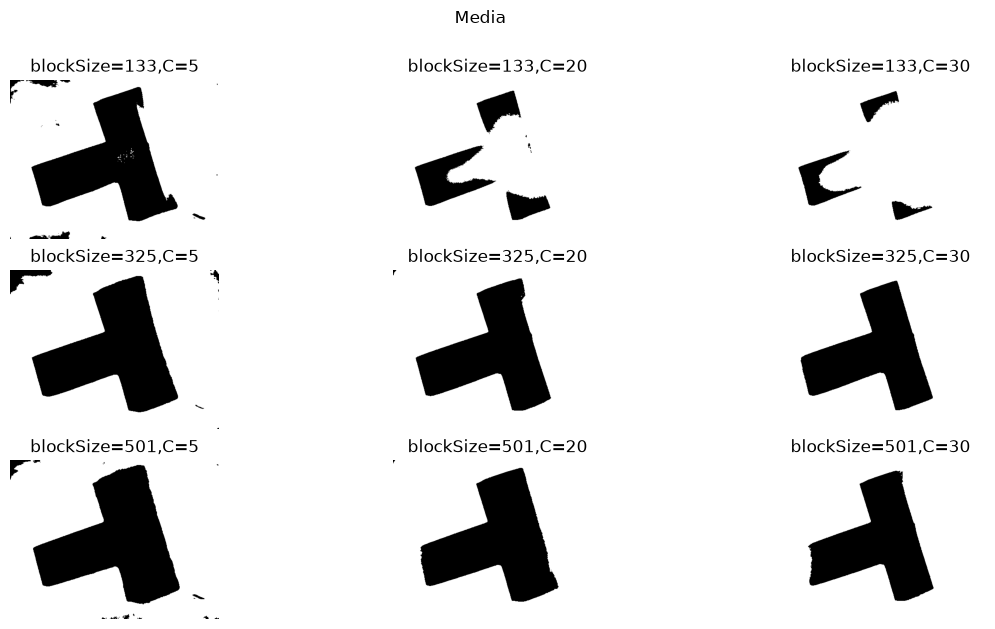

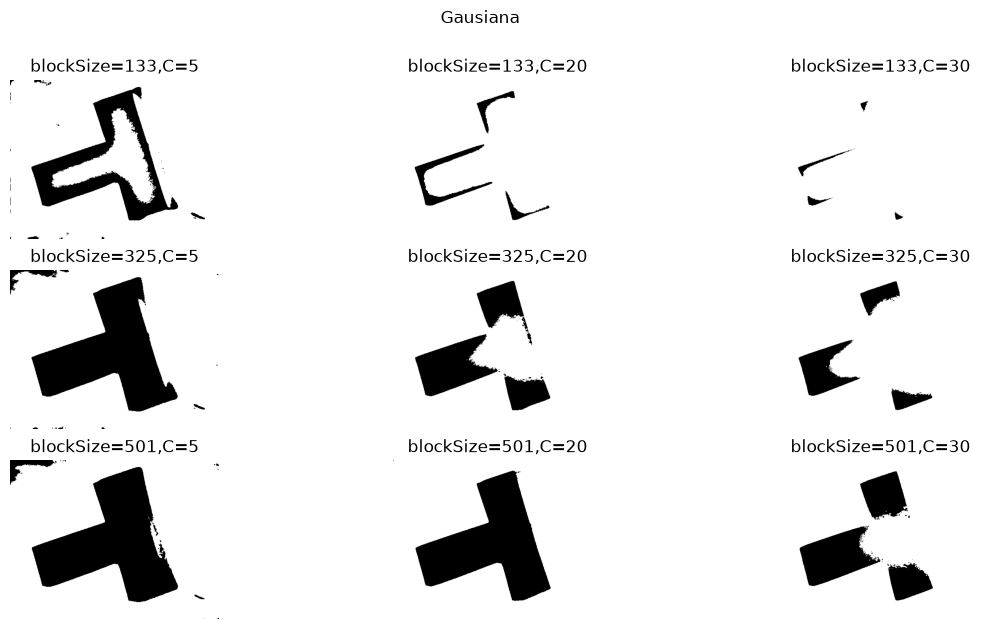

In [12]:
#| echo: false
#| label: fig-local-t
#| fig-cap: "Ajuste de parámetros para la umbralización local"
#| fig-subcap:
#|  - "Imagen original"
#|  - "Aplicación de umbralización local, usando la media"
#|  - "Aplicación de umbralización local, usando la gausiana"
#| layout: [[1], [1, 1]]
img = images[1]['array']
blur = cv.GaussianBlur(img, ksize=(5, 5), sigmaX=0)
th = cv.adaptiveThreshold(blur, 255, cv.ADAPTIVE_THRESH_MEAN_C, cv.THRESH_BINARY, 19, 12)

plot_image(blur, axis=True)

for metodo in (cv.ADAPTIVE_THRESH_MEAN_C, cv.ADAPTIVE_THRESH_GAUSSIAN_C):
    fig, axes = plt.subplots(3, 3, figsize=(14, 7))
    axes = axes.ravel()

    for i ,(blockSize, C) in enumerate(product((133, 325, 501), (5, 20, 30))):
        th = cv.adaptiveThreshold(blur, 255, metodo, cv.THRESH_BINARY, blockSize, C)
        plot_image(th, ax=axes[i], title=f'blockSize={blockSize},C={C}')

    fig.suptitle('Media' if metodo==cv.ADAPTIVE_THRESH_MEAN_C else 'Gausiana')

## K-means clustering

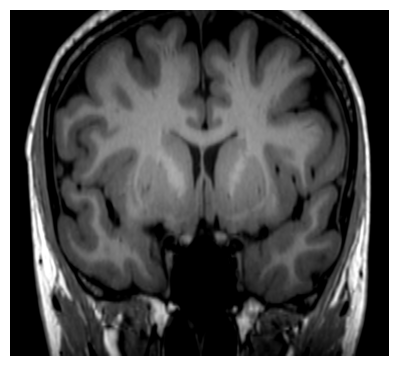

In [13]:
#| include: false
img = cv.imread(DATA_DIR / 'brain1.png', cv.IMREAD_GRAYSCALE)

plot_image(img)

plt.show()

La imagen brain1.png corresponde a una resonancia magnética cerebral en escala de grises.

La @fig-kmeans-original-histogram muestra la imagen original con su histograma de intensidades, se observa una concentración elevada en las intensidades bajas, asociadas a las regiones oscuras y al fondo de la imagen.

se muestra el histograma de la imagen para ver como se reparte la intensidad de grises en la imagen.

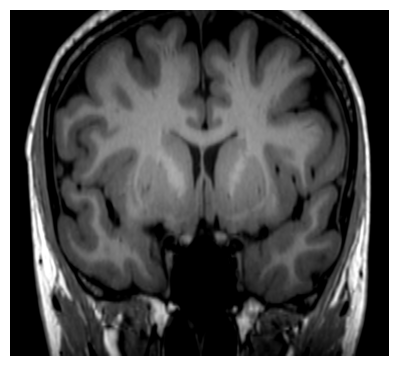

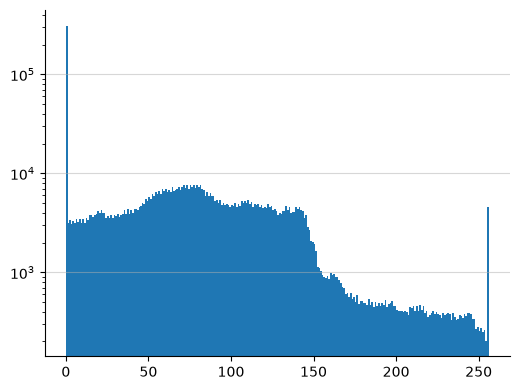

In [14]:
#| echo: false
#| label: fig-kmeans-original-histogram
#| fig-cap: "Resonancia magnética cerebral"
#| fig-subcap:
#|  - "Imagen original"
#|  - "Histograma de intensidades de la imagen original"
#| layout-ncol: 2

plot_image(img)
plot_histogram(img, scale='log')

plt.show()

La @fig-kmeans-histogram muestra los resultados de aplicar el K-means con diferente número de clústeres. Para cada configuración se muestra la imagen segmentada junto con el histograma de intensidades original, coloreado según los grupos obtenidos, las líneas verticales naranjas indican la posición de los centroides calculados por el algoritmo.

Para valores reducidos de k, como k=2 y k=3, la segmentación permite diferenciar regiones más oscuras de las estructuras del cerebro, pero se pierde el detalle anatómico.

Al aumentar el número de clusters k=5 y k=7, presenta una mayor variedad de intensidades intermedias y altas. Esto permite visualizar más estructuras del tejido cerebral.

Para k=12 y k=15 se incorporan nuevos centroides que mejoran la representación de las transiciones entre niveles de gris permitiendo distinguir más detalles de la imagen.

Los resultados muestran que aumentar el número de clústeres mejora la fidelidad de la imagen segmentada pero aumenta la complejidad de la imagen.

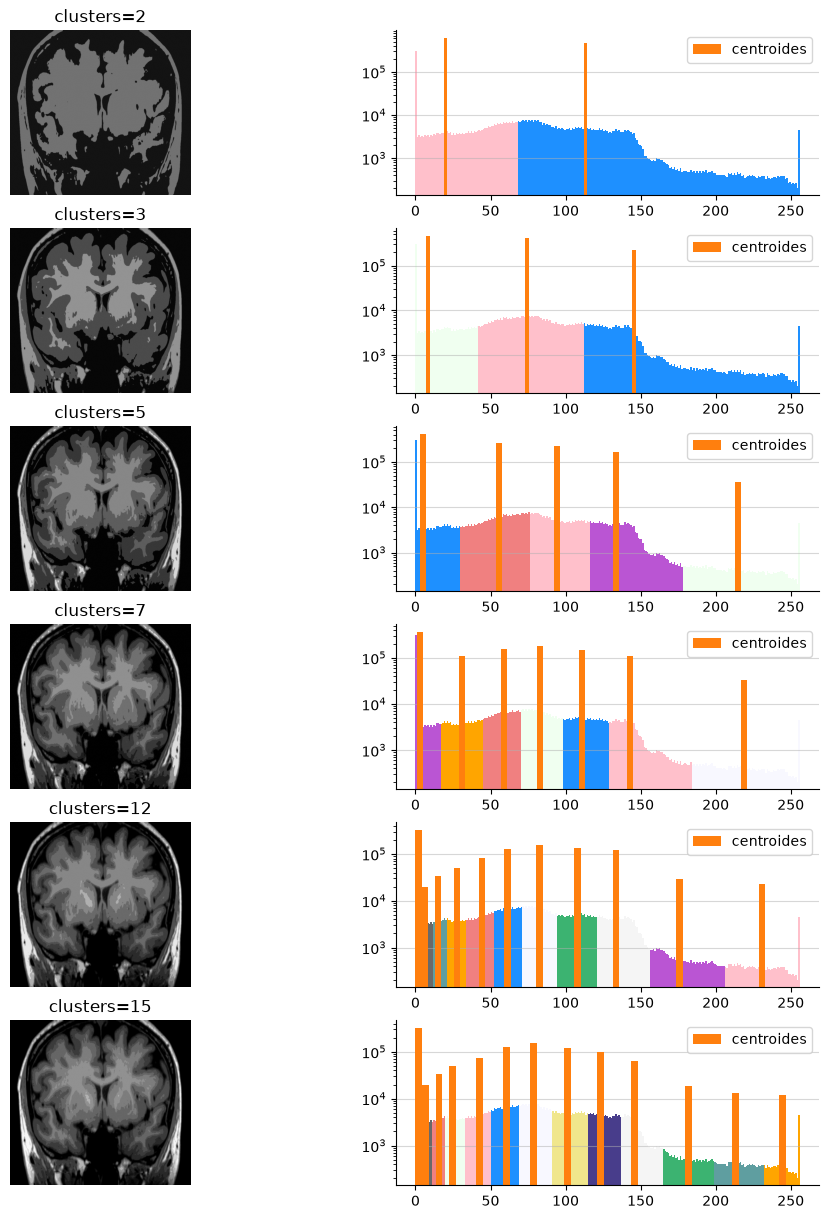

In [ ]:
#| echo: false
#| label: fig-kmeans-histogram
#| fig-cap: "Segmentación mediante K-means para distintos números de clústeres"
CRITERIA = (cv.TERM_CRITERIA_EPS + cv.TERM_CRITERIA_MAX_ITER, 10, 1.0)
FLAGS = cv.KMEANS_RANDOM_CENTERS

Z = img.reshape((-1, 1))
Z = np.float32(Z)
kms = []

for K in (2, 3, 5, 7, 12, 15):
    compactness, labels, centers = cv.kmeans(Z,K,None, CRITERIA, 10, FLAGS)
    # print(f'compactness es de {compactness:.2f} para {K} clusters')

    centers = np.uint8(centers)
    labels = labels.flatten()
    res = centers[labels]

    kms.append({
        'n_cluster': K,
        'centers': res,
        'labels': labels,
        'img': res.reshape(img.shape)
    })

fig, axes = plt.subplots(6, 2, figsize=(12, 15))

for i, km in enumerate(kms):
    n_cluster = km['n_cluster']
    centers = km['centers']
    labels = km['labels']
    img_compress = km['img']

    plot_image(img_compress, ax=axes[i, 0], title=f'clusters={n_cluster}')
    plot_histogram(img, ax=axes[i, 1], centroids=centers, labels=labels, scale='log')

## Segmetación con MeanShift

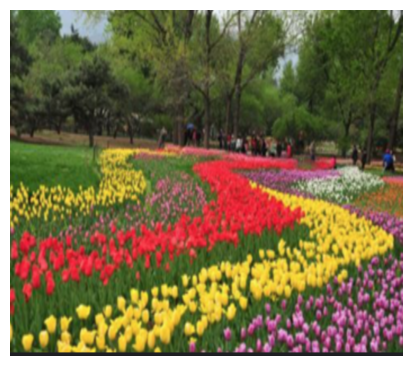

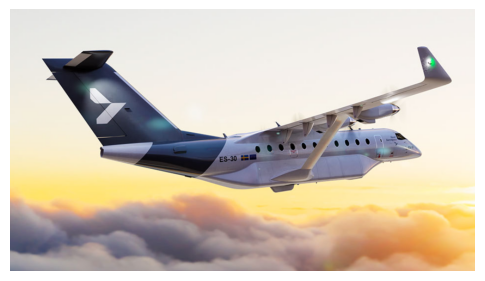

In [16]:
#| include: false
img_garden = cv.imread(DATA_DIR / 'jardin1.png')
img_plane = cv.imread(DATA_DIR / 'avion1.png')


plot_image(img_garden, convert=cv.COLOR_BGR2RGB)
plot_image(img_plane, convert=cv.COLOR_BGR2RGB)

plt.show()

El algoritmo Mean Shift que nos permite suavizar una imagen conservando los bordes. OpenCV proporciona una implementación de este algoritmo, funciona desplazando de forma iterativa una ventana de búsqueda hacia regiones de mayor densidad en el espacio conjunto de espacio y color. Para ello, se consideran los píxeles que cumplen las siguientes condiciones:

$$
\left\{
(x,y):
\begin{aligned}
X-\texttt{sp} &\leq x \leq X+\texttt{sp},\\
Y-\texttt{sp} &\leq y \leq Y+\texttt{sp},\\
\|(R,G,B)-(r,g,b)\|_2 &\leq \texttt{sr}
\end{aligned}
\right\}
$$

Donde:

- **sp:** representa el radio de la ventana espacial y determina la distancia máxima considerada entre píxeles vecinos.
- **sr:** establece el radio de similitud cromática, limitando la diferencia de color entre los píxeles considerados.
- **(X,Y):** corresponde a la posición central de la ventana de búsqueda.
- **(R,G,B):** representa el color de referencia de la ventana.

Mediante este proceso, los píxeles con características espaciales y cromáticas similares convergen hacia valores representativos próximos, dando lugar a regiones de color más uniforme.

La @fig-meanshift-params presenta los resultados de aplicar Mean Shift con diferentes valores de los parámetros sp y sr, con el objetivo de analizar su influencia en el suavizado y la conservación de los detalles.

En la @fig-meanshift-params-1 se aumenta el radio espacial, manteniedo el mismo radio de color. Al aumentar el radio espacial, el algoritmo considera vecinos píxeles más alejados favoreciendo la formación de regiones homogéneas más grandes, se reducen detalles pero las estructuras principales permanecen reconocibles.

En la @fig-meanshift-params-2 mantiene el radio espacial y se incrementa el radio de color. El aumento del radio de color permite agrupar píxeles con diferencias de color mayores, lo que se traduce en un suavizado más intenso.

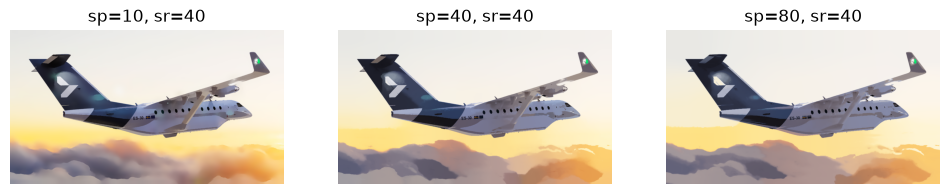

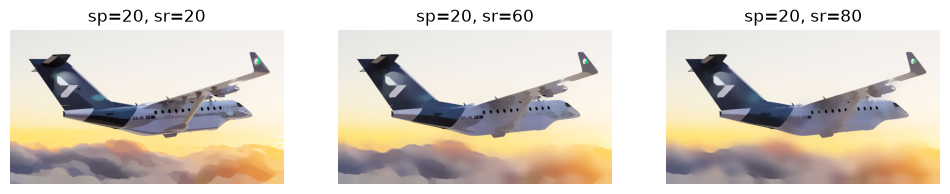

In [17]:
#| echo: false
#| label: fig-meanshift-params
#| fig-cap: "Efecto de los parámetros en el filtrado Mean Shift"
#| fig-subcap:
#|  - "Variación del radio espcial"
#|  - "variación del radio de color"
#| layout-nrows: 2
pairs = [
    (10, 40),
    (40, 40),
    (80, 40),
    (20, 20),
    (20, 60),
    (20, 80)
]


fig, axes = plt.subplots(1, 3, figsize=(12, 4.5))

for i, (spatial_radius, color_radius) in enumerate(pairs[:3]):
    shifted = cv.pyrMeanShiftFiltering(img_plane, sp=spatial_radius, sr=color_radius)
    plot_image(shifted, ax=axes[i], title=f'sp={spatial_radius}, sr={color_radius}', convert=cv.COLOR_BGR2RGB)

fig, axes = plt.subplots(1, 3, figsize=(12, 4.5))

for i, (spatial_radius, color_radius) in enumerate(pairs[3:]):
    shifted = cv.pyrMeanShiftFiltering(img_plane, sp=spatial_radius, sr=color_radius)
    plot_image(shifted, ax=axes[i], title=f'sp={spatial_radius}, sr={color_radius}', convert=cv.COLOR_BGR2RGB)

El parámetro maxLevel, establece el nivel máximo de una pirámide guassiana empleada durante el procesamiento en maxLevel+1.

![Pirámide gaussiana. Fuente: Branch y Stewart (2018) [@branch2018gaussian].](assets/piramide-gaussiana.png){#fig-piramide width=75%}

En la @fig-meanshift-max-levels se comparan los resultados con distintos niveles de maxLevel. Las tres configuraciones mantienen las principales regiones de color y la estructura general de la escena, las diferencia aparecen principalmente en las zonas con variaciones locales de color y en delimitación de algunas regiones.

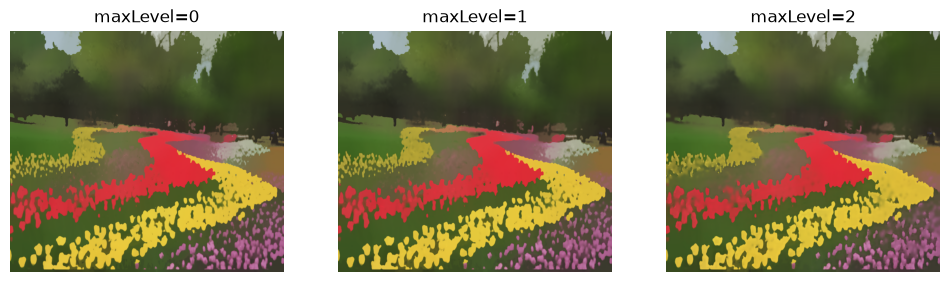

In [18]:
#| echo: false
#| label: fig-meanshift-max-levels
#| fig-cap: "Resultado de pirámides gaussianas al aplicar mean shift"
fig, axes = plt.subplots(1, 3, figsize=(12, 4.5))
axes = axes.ravel()

for i in range(3):
    shifted = cv.pyrMeanShiftFiltering(img_garden, sp=30, sr=60, maxLevel=i)
    plot_image(shifted, ax=axes[i], title=f'maxLevel={i}', convert=cv.COLOR_BGR2RGB)

## Segmentación Watershed

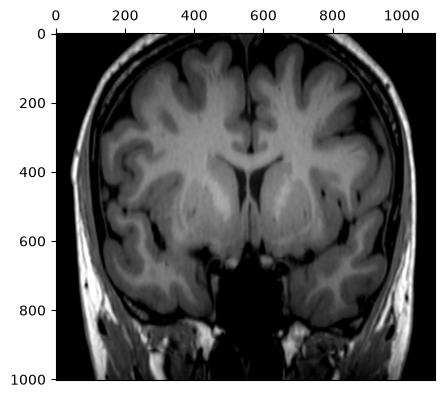

In [239]:
#| include: false
img = cv.imread(DATA_DIR / 'brain1.png')

plot_image(img, axis=True)

plt.show()

En la figura @fig-exercise-5-4-1 se muestra la segmentación de los lóbulos cerebrales utilizando un umbral de Otsu sobre la imagen suavizada y enmascarada con una elipse que representa la región del cerebro.

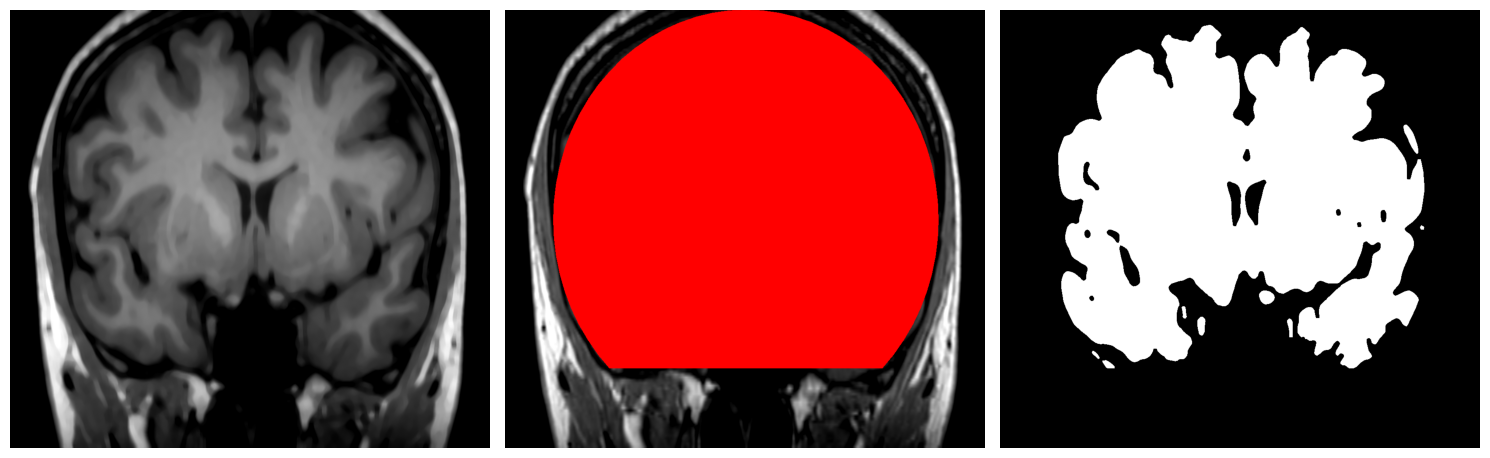

In [360]:
#| echo: false
#| label: fig-exercise-5-4-1
#| fig-cap: "Segmentación de los lóbulos cerebrales"
img_gray = cv.cvtColor(img, cv.COLOR_RGB2GRAY)
img_smooth = cv.medianBlur(img_gray, 15)

img_tmp = img.copy()
brain_mask = cv.ellipse(np.zeros_like(img_gray), (550, 480), (440, 480), 0, 0, 360, 1, -1)
brain_mask[820:, :] = 0
img_tmp[brain_mask == 1] = (255, 0, 0)

_, img_thresh = cv.threshold(img_smooth * brain_mask, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)

plot_list_images([img_smooth, img_tmp, img_thresh])
plt.show()

In [ ]:
#| include: false
# Fondo seguro
kernel = cv.getStructuringElement(cv.MORPH_ELLIPSE, (20, 20))
sure_bg = cv.dilate(img_thresh, kernel, iterations=2)

# Primer plano seguro
eroded = cv.erode(img_thresh, kernel, iterations=3)
dist_transform = cv.distanceTransform(eroded, cv.DIST_L2, 3)
_, sure_fg = cv.threshold(dist_transform, 0.16 * dist_transform.max(), 255, 0)
sure_fg = np.uint8(sure_fg)

# Región desconocida
unknown = cv.subtract(sure_bg, sure_fg)

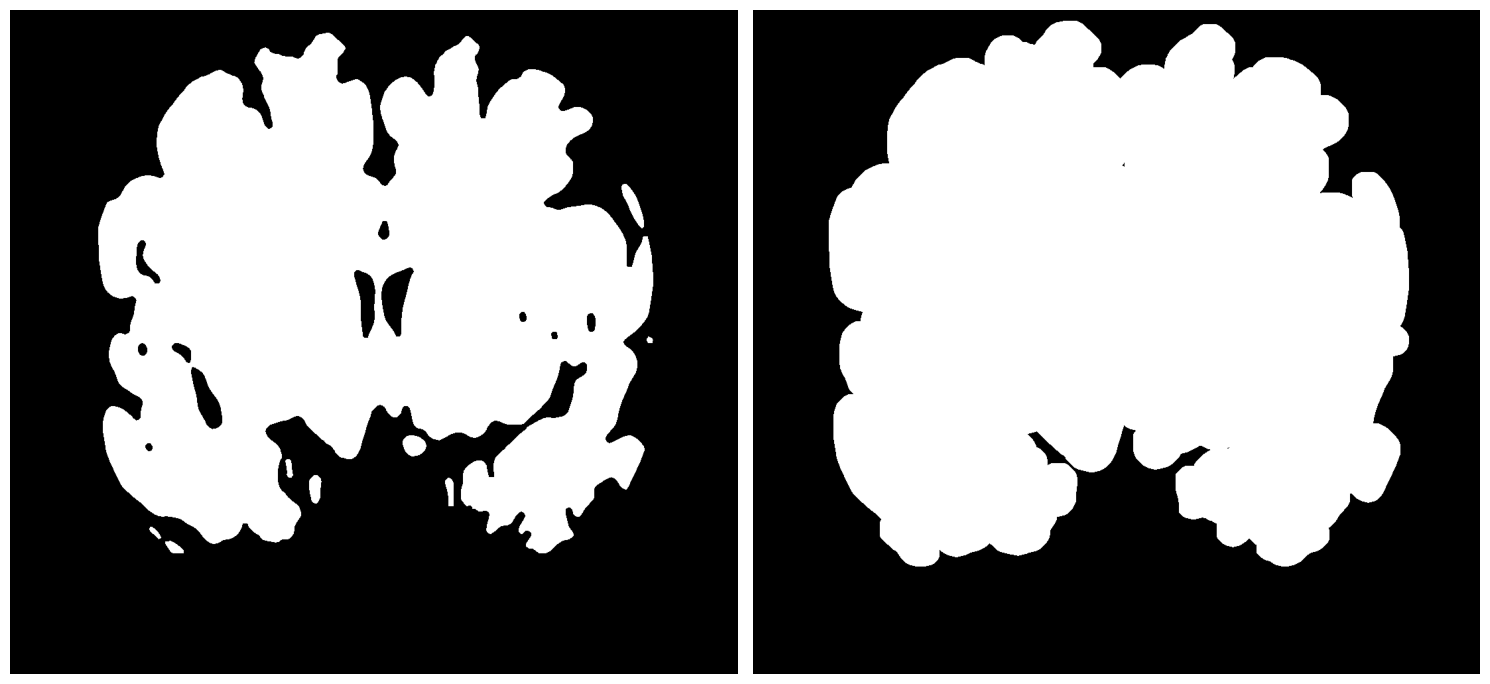

In [362]:
#| include: false
# Contrucción del fondo seguro agregando una dilatación alta sobre las imagen segementada
plot_list_images([img_thresh, sure_bg])
plt.show()

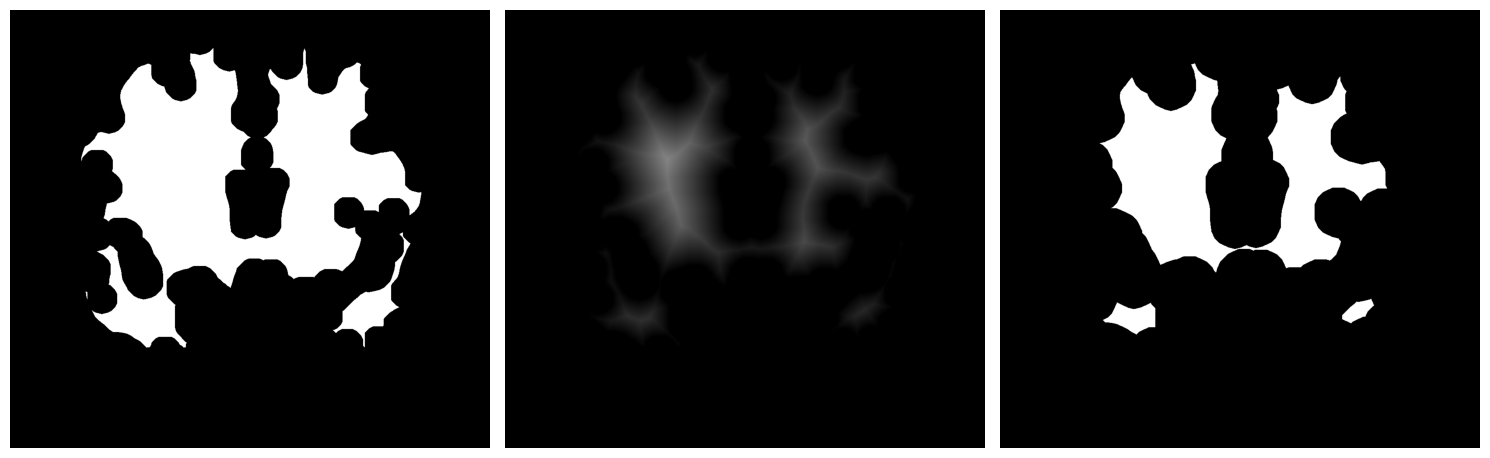

In [364]:
#| include: false
# Visualización del cálculo del primer plano seguro
#   - Erosión sobre la imagen segmemntada para que los lóbulos cerebrales queden más definidos
#   - Transformada de distancia para resaltar las regiones centrales de los lóbulos
#   - Umbral sobre la transformada de distancia para obtener el primer plano seguro
plot_list_images([eroded, dist_transform, sure_fg])
plt.show()

En la @fig-exercise-5-4-2-1 se muestran las transformaciones de fondo seguro, primer plano seguro y región desconocida que se utilizan para construir la máscara de regiones segmentadas, @fig-exercise-5-4-2-2, que es utilizada como semilla por el algoritmo de watershed.

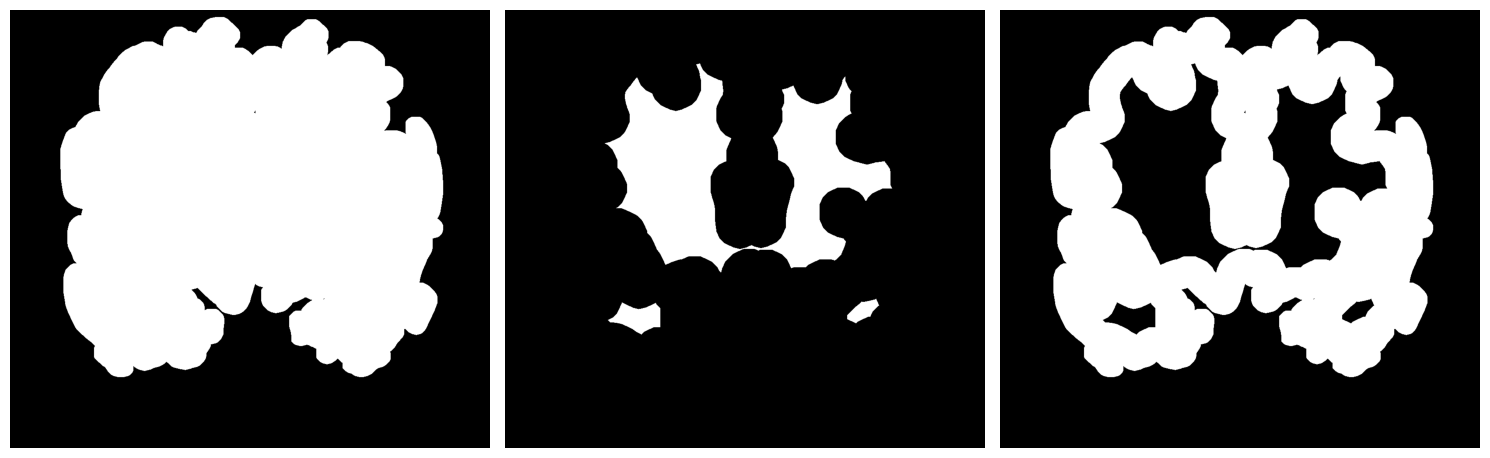

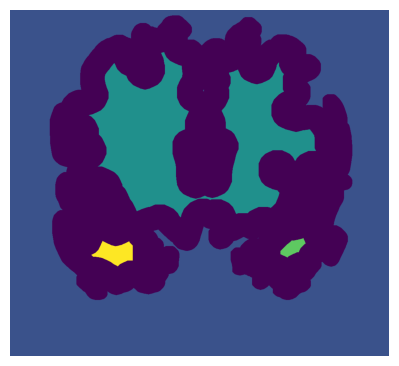

In [ ]:
#| echo: false
#| label: fig-exercise-5-4-2
#| fig-cap: "Transformaciones intermedias"
#| fig-subcap:
#|  - "Fondo seguro, primer plano seguro y región desconocida"
#|  - "Máscara de las regiones segmentadas"
#| layout-nrow: 2
_, markers = cv.connectedComponents(sure_fg)
markers = markers + 1
markers[unknown == 255] = 0

plot_list_images([sure_bg, sure_fg, unknown])

fig, ax = plt.subplots()
ax.imshow(markers)
ax.axis('off')
plt.show()

En la @fig-exercise-5-4-3 se muestra el resultado de la aplicación del algoritmo watershed para la separación de los lóbulos.

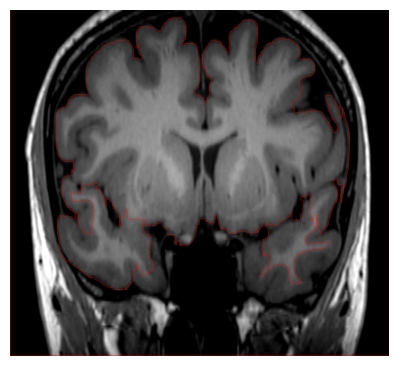

In [373]:
#| echo: false
#| label: fig-exercise-5-4-3
#| fig-cap: "Separación de los lóbulos con watershed"
#| layout-nrow: 2
markers_cv = cv.watershed(img, markers)
resultado = img.copy()
resultado[markers_cv == -1] = (255, 0, 0)


plot_image(resultado)
plt.show()